In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import norm, ttest_ind, shapiro, chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix

In [4]:
df = pd.read_csv("Sample-Superstore.csv")
print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156  11-08-2016  11-11-2016    Second Class    CG-12520   
1       2  CA-2016-152156  11-08-2016  11-11-2016    Second Class    CG-12520   
2       3  CA-2016-138688  06-12-2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10-11-2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10-11-2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Cate

In [5]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)
print("\nDataset Information:")
df.info()
print("\nFirst 5 Records:")
display(df.head())

Shape: (9994, 21)

Columns:
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State         

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Duplicate Records:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())
print("\nData Types:")
print(df.dtypes)

Total Records: 9994
Total Columns: 21
Duplicate Records: 0
Missing Values: 0

Data Types:
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [7]:
sales_array = np.array(df["Sales"])
profit_array = np.array(df["Profit"])
print("Sales Array:", sales_array[:10])
print("Mean Sales:", np.mean(sales_array))
print("Maximum Sales:", np.max(sales_array))
print("Minimum Sales:", np.min(sales_array))
print("Total Sales:", np.sum(sales_array))

Sales Array: [261.96   731.94    14.62   957.5775  22.368   48.86     7.28   907.152
  18.504  114.9   ]
Mean Sales: 229.85800083049827
Maximum Sales: 22638.48
Minimum Sales: 0.444
Total Sales: 2297200.8603


In [7]:
quantity_array = np.array(df["Quantity"])
print("Addition:", quantity_array + 2)
print("Multiplication:", quantity_array * 2)
print("Square:", np.square(quantity_array))
print("Standard Deviation:", np.std(sales_array))

Addition: [4 5 4 ... 4 6 4]
Multiplication: [4 6 4 ... 4 8 4]
Square: [ 4  9  4 ...  4 16  4]
Standard Deviation: 623.2139187650461


In [8]:
sales_series = pd.Series(df["Sales"])
print("Series:")
print(sales_series.head())
print("\nDataFrame:")
display(df.head())
print("\nSales Description:")
print(sales_series.describe())

Series:
0    261.9600
1    731.9400
2     14.6200
3    957.5775
4     22.3680
Name: Sales, dtype: float64

DataFrame:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



Sales Description:
count     9994.000000
mean       229.858001
std        623.245101
min          0.444000
25%         17.280000
50%         54.490000
75%        209.940000
max      22638.480000
Name: Sales, dtype: float64


In [9]:
print("Before Cleaning:", df.shape)
df = df.drop_duplicates()
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="mixed")
df = df.dropna(subset=["Sales", "Profit", "Quantity"])
df = df[df["Sales"] >= 0]
print("After Cleaning:", df.shape)
print("Missing Values:")
print(df.isnull().sum())

Before Cleaning: (9994, 21)
After Cleaning: (9994, 21)
Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [10]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [11]:
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Profit Margin"] = np.where(
    df["Sales"] != 0,
    (df["Profit"] / df["Sales"]) * 100,
    0
)

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Month Name,Shipping Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,7,11.25


In [12]:
print("Final Dataset Shape:", df.shape)
print("Total Records:", len(df))

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

df.head()

Final Dataset Shape: (9994, 26)
Total Records: 9994

Missing Values: 0
Duplicate Records: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Month Name,Shipping Days,Profit Margin
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October,7,11.25


In [13]:
df.to_csv("Cleaned_Retail_Dataset.csv", index=False)

print("Cleaned Dataset Saved Successfully")

Cleaned Dataset Saved Successfully


In [14]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
average_sales = df["Sales"].mean()
average_profit = df["Profit"].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Average Sales:", round(average_sales, 2))
print("Average Profit:", round(average_profit, 2))

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Average Sales: 229.86
Average Profit: 28.66


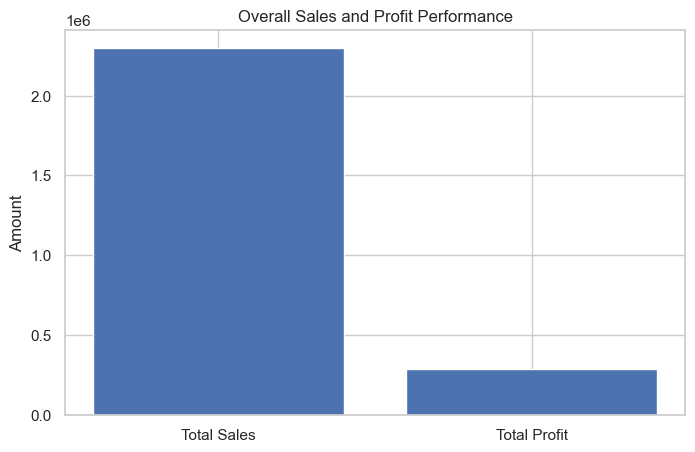

In [15]:
plt.figure(figsize=(8, 5))

values = [total_sales, total_profit]
labels = ["Total Sales", "Total Profit"]

plt.bar(labels, values)
plt.title("Overall Sales and Profit Performance")
plt.ylabel("Amount")
plt.show()

In [16]:
category_analysis = df.groupby("Category").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
})

print(category_analysis)

                       Sales       Profit  Quantity
Category                                           
Furniture        741999.7953   18451.2728      8028
Office Supplies  719047.0320  122490.8008     22906
Technology       836154.0330  145454.9481      6939


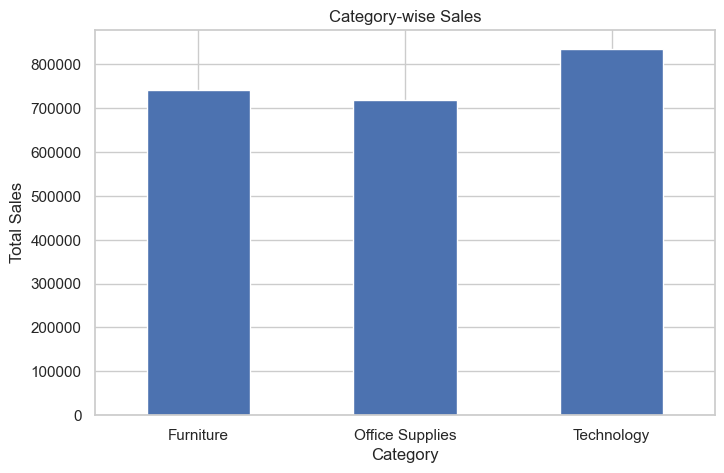

In [17]:
category_analysis["Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Category-wise Sales"
)

plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

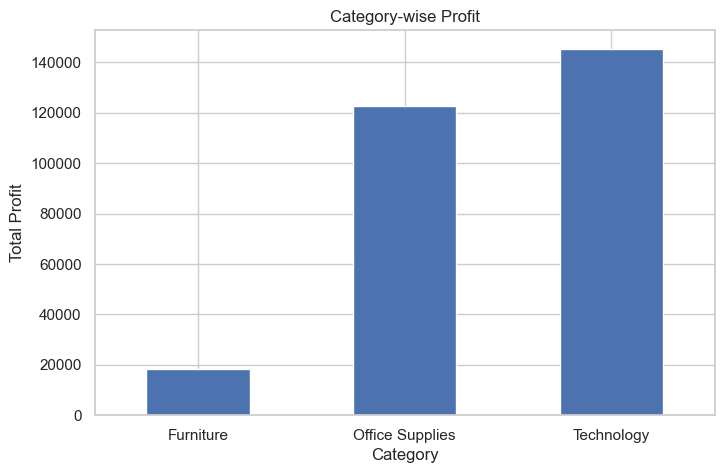

In [18]:
category_analysis["Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Category-wise Profit"
)

plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.show()

In [20]:
subcategory_analysis = df.groupby("Sub-Category").agg({
    "Sales": "sum",
    "Profit": "sum"
}).sort_values("Profit", ascending=False)

print(subcategory_analysis)

                    Sales      Profit
Sub-Category                         
Copiers       149528.0300  55617.8249
Phones        330007.0540  44515.7306
Accessories   167380.3180  41936.6357
Paper          78479.2060  34053.5693
Binders       203412.7330  30221.7633
Chairs        328449.1030  26590.1663
Storage       223843.6080  21278.8264
Appliances    107532.1610  18138.0054
Furnishings    91705.1640  13059.1436
Envelopes      16476.4020   6964.1767
Art            27118.7920   6527.7870
Labels         12486.3120   5546.2540
Machines      189238.6310   3384.7569
Fasteners       3024.2800    949.5182
Supplies       46673.5380  -1189.0995
Bookcases     114879.9963  -3472.5560
Tables        206965.5320 -17725.4811


In [21]:
print("Top 5 Profitable Sub-Categories:")
print(subcategory_analysis.head(5))

print("\nBottom 5 Sub-Categories:")
print(subcategory_analysis.tail(5))

Top 5 Profitable Sub-Categories:
                   Sales      Profit
Sub-Category                        
Copiers       149528.030  55617.8249
Phones        330007.054  44515.7306
Accessories   167380.318  41936.6357
Paper          78479.206  34053.5693
Binders       203412.733  30221.7633

Bottom 5 Sub-Categories:
                    Sales      Profit
Sub-Category                         
Machines      189238.6310   3384.7569
Fasteners       3024.2800    949.5182
Supplies       46673.5380  -1189.0995
Bookcases     114879.9963  -3472.5560
Tables        206965.5320 -17725.4811


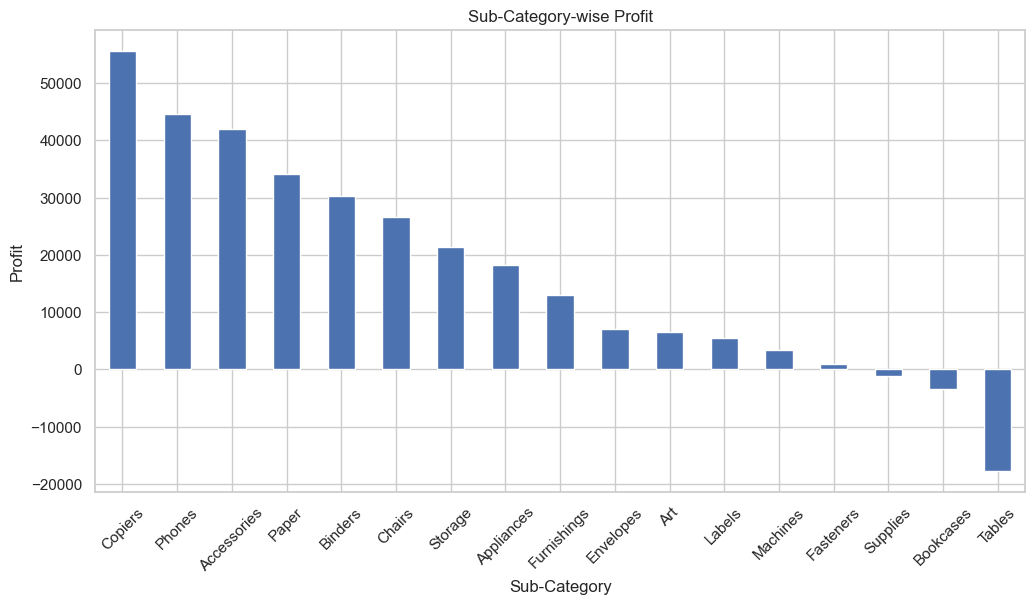

In [22]:
subcategory_analysis["Profit"].plot(
    kind="bar",
    figsize=(12, 6),
    title="Sub-Category-wise Profit"
)

plt.xlabel("Sub-Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.show()

In [23]:
segment_analysis = df.groupby("Segment").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum",
    "Customer ID": "nunique"
})

print(segment_analysis)

                    Sales       Profit  Quantity  Customer ID
Segment                                                      
Consumer     1.161401e+06  134119.2092     19521          409
Corporate    7.061464e+05   91979.1340     11608          236
Home Office  4.296531e+05   60298.6785      6744          148


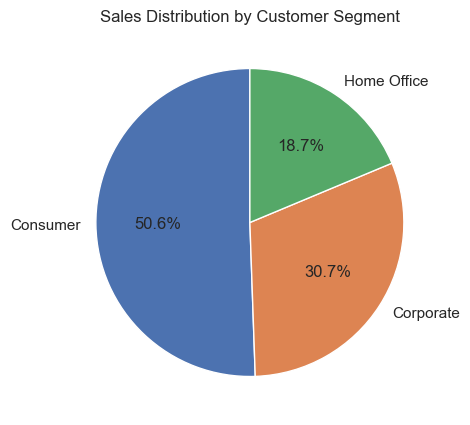

In [24]:
plt.figure(figsize=(8, 5))

plt.pie(
    segment_analysis["Sales"],
    labels=segment_analysis.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Distribution by Customer Segment")
plt.show()

In [25]:
top_customers = df.groupby("Customer Name")["Sales"].sum()

top_customers = top_customers.sort_values(
    ascending=False
).head(10)

print(top_customers)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


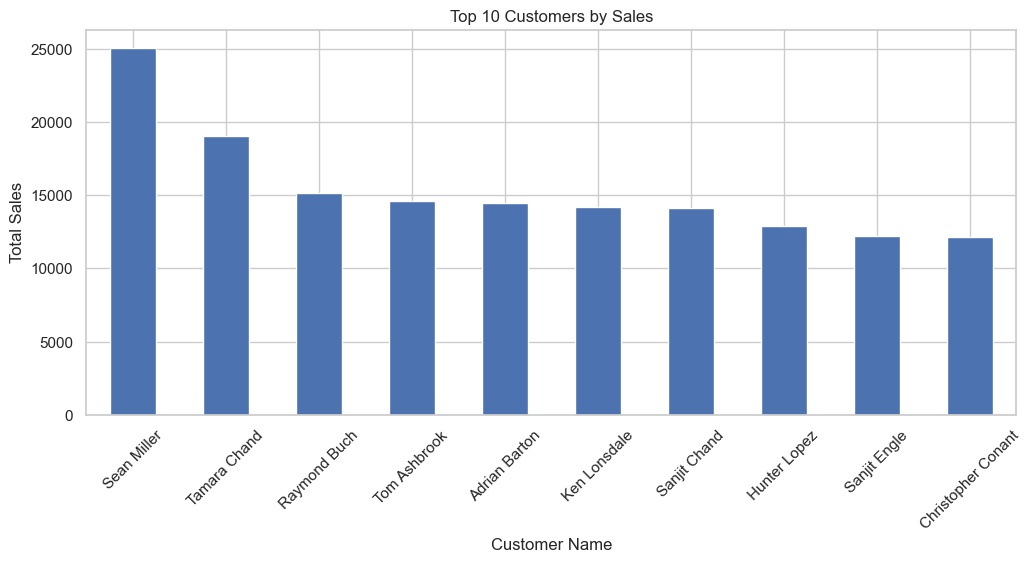

In [26]:
top_customers.plot(
    kind="bar",
    figsize=(12, 5),
    title="Top 10 Customers by Sales"
)

plt.xlabel("Customer Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [27]:
region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Quantity": "sum"
})

print(region_analysis)

               Sales       Profit  Quantity
Region                                     
Central  501239.8908   39706.3625      8780
East     678781.2400   91522.7800     10618
South    391721.9050   46749.4303      6209
West     725457.8245  108418.4489     12266


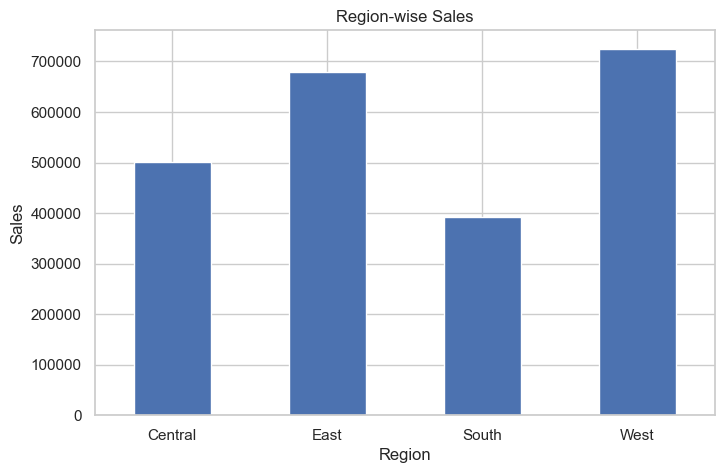

In [28]:
region_analysis["Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Region-wise Sales"
)

plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

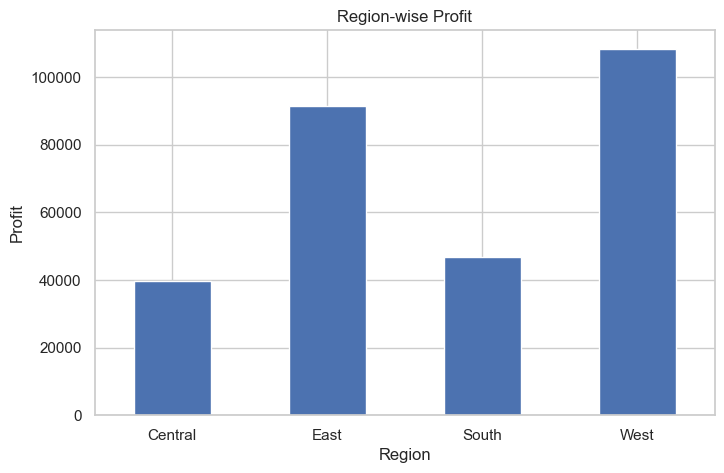

In [29]:
region_analysis["Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Region-wise Profit"
)

plt.xlabel("Region")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.show()

In [30]:
yearly_sales = df.groupby("Order Year")["Sales"].sum()

print(yearly_sales)

Order Year
2014    484247.4981
2015    470532.5090
2016    609205.5980
2017    733215.2552
Name: Sales, dtype: float64


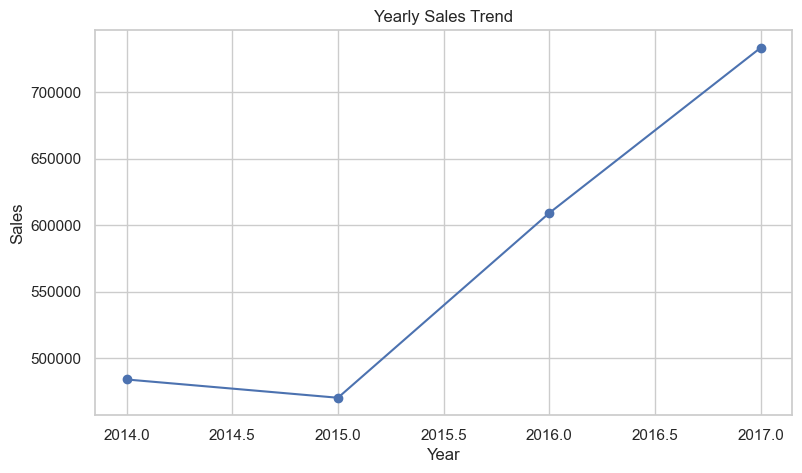

In [31]:
yearly_sales.plot(
    kind="line",
    marker="o",
    figsize=(9, 5),
    title="Yearly Sales Trend"
)

plt.xlabel("Year")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

In [32]:
monthly_sales = df.groupby("Order Month")["Sales"].sum()

print(monthly_sales)

Order Month
1      94924.8356
2      59751.2514
3     205005.4888
4     137762.1286
5     155028.8117
6     152718.6793
7     147238.0970
8     159044.0630
9     307649.9457
10    200322.9847
11    352461.0710
12    325293.5035
Name: Sales, dtype: float64


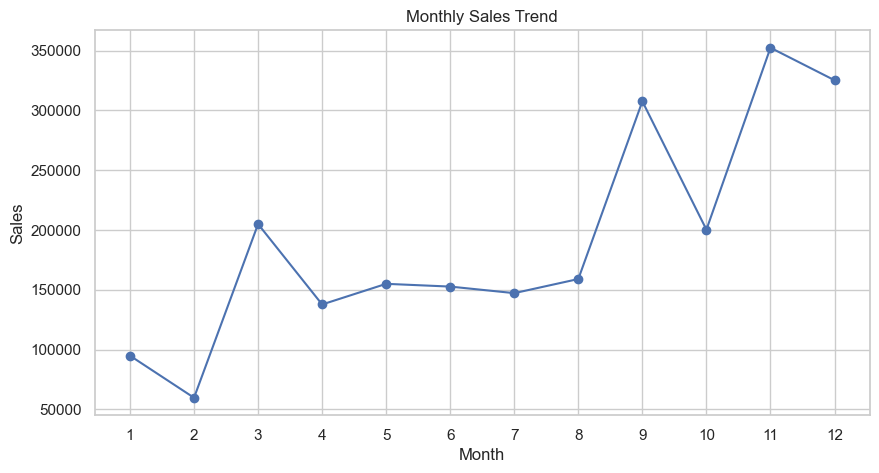

In [33]:
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

In [34]:
discount_analysis = df.groupby("Discount").agg({
    "Sales": "sum",
    "Profit": "sum"
})

print(discount_analysis)

                 Sales       Profit
Discount                           
0.00      1.087908e+06  320987.6032
0.10      5.436935e+04    9029.1770
0.15      2.755852e+04    1418.9915
0.20      7.645944e+05   90337.3060
0.30      1.032267e+05  -10369.2774
0.32      1.449346e+04   -2391.1377
0.40      1.164178e+05  -23057.0504
0.45      5.484974e+03   -2493.1111
0.50      5.891854e+04  -20506.4281
0.60      6.644700e+03   -5944.6552
0.70      4.062028e+04  -40075.3569
0.80      1.696376e+04  -30539.0392


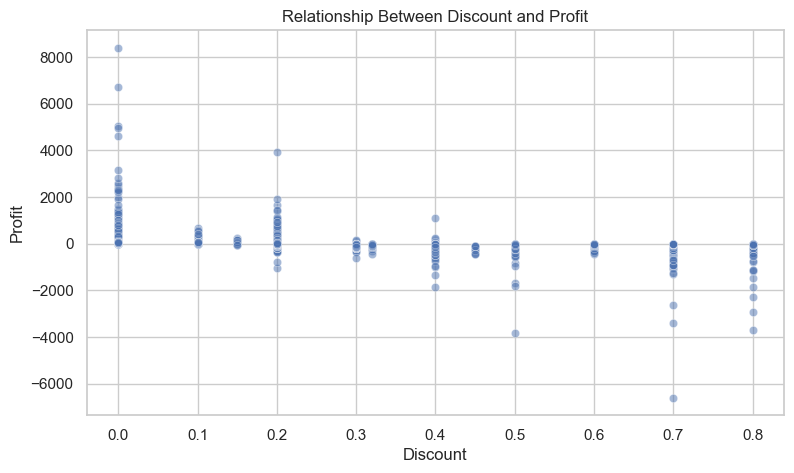

In [35]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    alpha=0.5
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

In [36]:
discount_correlation = df["Discount"].corr(df["Profit"])

print(
    "Correlation Between Discount and Profit:",
    round(discount_correlation, 3)
)

Correlation Between Discount and Profit: -0.219


In [37]:
shipping_analysis = df.groupby("Ship Mode").agg({
    "Sales": "sum",
    "Profit": "sum",
    "Order ID": "nunique",
    "Shipping Days": "mean"
})

print(shipping_analysis)

                       Sales       Profit  Order ID  Shipping Days
Ship Mode                                                         
First Class     3.514284e+05   48969.8399       787       2.182705
Same Day        1.283631e+05   15891.7589       264       0.044199
Second Class    4.591936e+05   57446.6354       964       3.238046
Standard Class  1.358216e+06  164088.7875      2994       5.006535


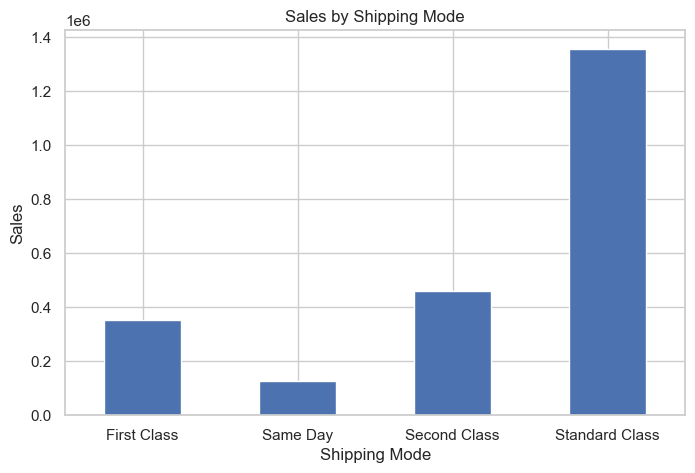

In [38]:
shipping_analysis["Sales"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Sales by Shipping Mode"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

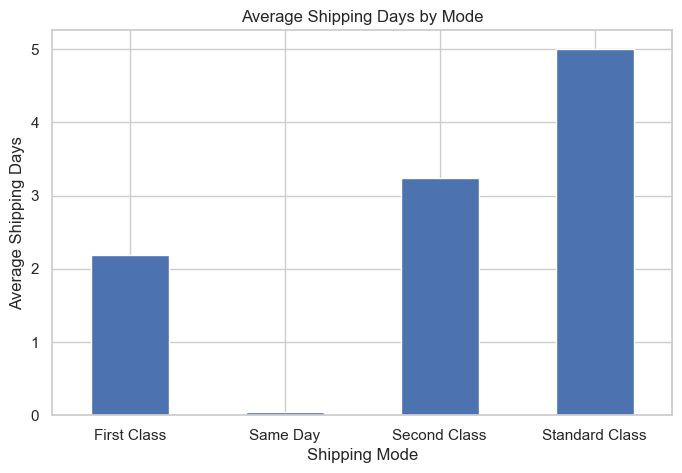

In [39]:
shipping_analysis["Shipping Days"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Shipping Days by Mode"
)

plt.xlabel("Shipping Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=0)
plt.show()

In [40]:
order_data = df.groupby("Order ID").agg({
    "Profit": "sum",
    "Discount": "mean"
}).reset_index()

order_data["Discount Type"] = np.where(
    order_data["Discount"] > 0,
    "Discounted",
    "Non-Discounted"
)

print(order_data.head())

         Order ID    Profit  Discount   Discount Type
0  CA-2014-100006  109.6113       0.0  Non-Discounted
1  CA-2014-100090  -19.0890       0.2      Discounted
2  CA-2014-100293   31.8696       0.2      Discounted
3  CA-2014-100328    1.3257       0.2      Discounted
4  CA-2014-100363    7.7192       0.2      Discounted


In [41]:
discounted = order_data[
    order_data["Discount Type"] == "Discounted"
]["Profit"]

non_discounted = order_data[
    order_data["Discount Type"] == "Non-Discounted"
]["Profit"]

print("Discounted Orders Sample Size:", len(discounted))
print("Non-Discounted Orders Sample Size:", len(non_discounted))

Discounted Orders Sample Size: 2954
Non-Discounted Orders Sample Size: 2055


In [42]:
mean_discounted = discounted.mean()
mean_non_discounted = non_discounted.mean()

print("Mean Profit of Discounted Orders:", round(mean_discounted, 2))
print("Mean Profit of Non-Discounted Orders:", round(mean_non_discounted, 2))

Mean Profit of Discounted Orders: 10.73
Mean Profit of Non-Discounted Orders: 123.94


In [43]:
alpha = 0.05

print("Significance Level:", alpha)
print("Test Type: Two-Sample Test")

Significance Level: 0.05
Test Type: Two-Sample Test


In [44]:
t_stat, p_value = ttest_ind(
    discounted,
    non_discounted,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

T-Statistic: -11.126792468285256
P-Value: 2.5543206293568983e-28


In [45]:
if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("There is a statistically significant difference in average profit.")
else:
    print("Fail to Reject the Null Hypothesis")
    print("There is insufficient evidence of a significant difference.")

Reject the Null Hypothesis
There is a statistically significant difference in average profit.


In [46]:
n1 = len(discounted)
n2 = len(non_discounted)

s1 = discounted.std()
s2 = non_discounted.std()

standard_error = np.sqrt(
    (s1**2 / n1) + (s2**2 / n2)
)

z_stat = (mean_discounted - mean_non_discounted) / standard_error

p_value_z = 2 * (1 - norm.cdf(abs(z_stat)))

print("Sample Mean 1:", mean_discounted)
print("Sample Mean 2:", mean_non_discounted)

print("Sample Size 1:", n1)
print("Sample Size 2:", n2)

print("Standard Error:", standard_error)
print("Z-Statistic:", z_stat)
print("P-Value using Normal CDF:", p_value_z)

Sample Mean 1: 10.733832938388623
Sample Mean 2: 123.9363889051095
Sample Size 1: 2954
Sample Size 2: 2055
Standard Error: 10.17387142695279
Z-Statistic: -11.126792468285256
P-Value using Normal CDF: 0.0


In [47]:
if p_value_z < alpha:
    print("Reject the Null Hypothesis")
else:
    print("Fail to Reject the Null Hypothesis")

Reject the Null Hypothesis


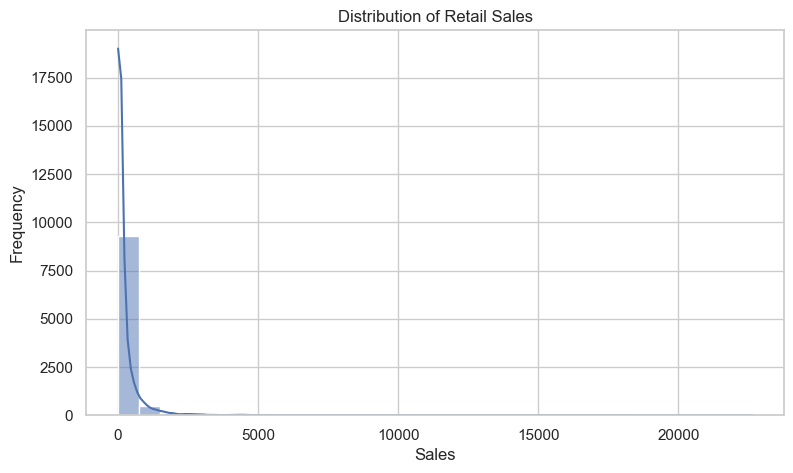

In [48]:
plt.figure(figsize=(9, 5))

sns.histplot(df["Sales"], bins=30, kde=True)

plt.title("Distribution of Retail Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

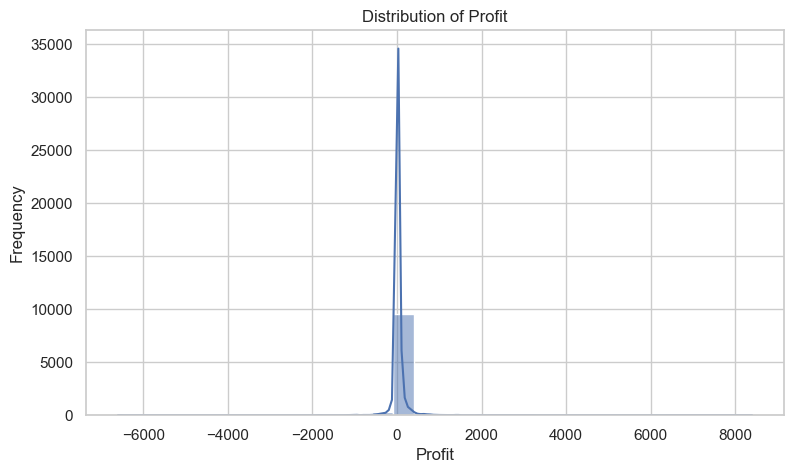

In [49]:
plt.figure(figsize=(9, 5))

sns.histplot(df["Profit"], bins=30, kde=True)

plt.title("Distribution of Profit")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

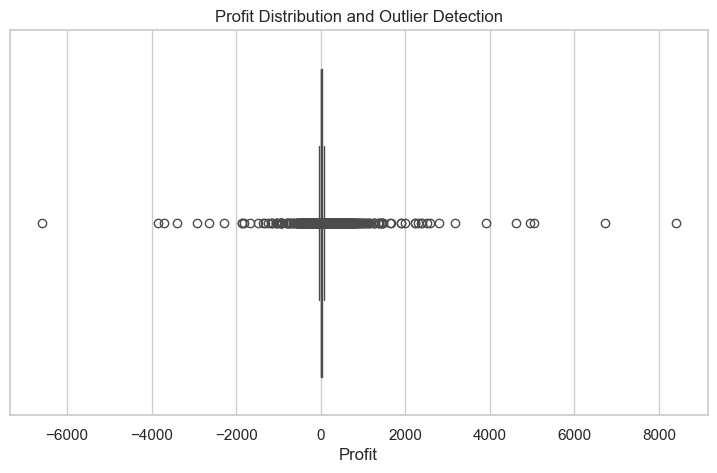

In [50]:
plt.figure(figsize=(9, 5))

sns.boxplot(x=df["Profit"])

plt.title("Profit Distribution and Outlier Detection")
plt.xlabel("Profit")
plt.show()

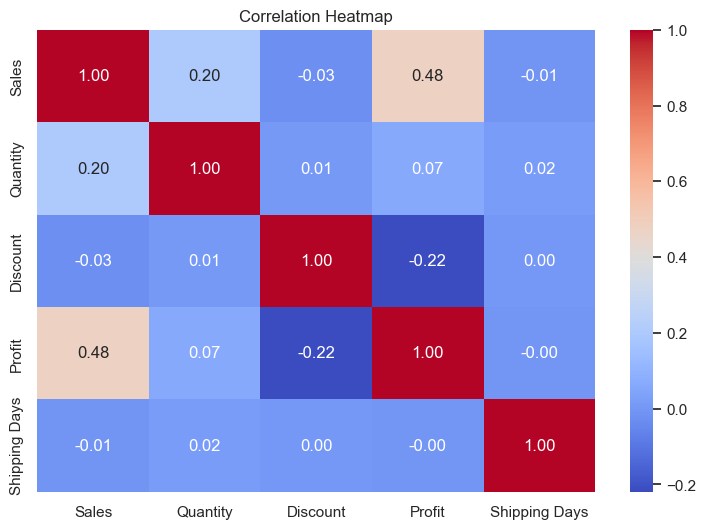

In [51]:
plt.figure(figsize=(9, 6))

correlation = df[
    ["Sales", "Quantity", "Discount", "Profit", "Shipping Days"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

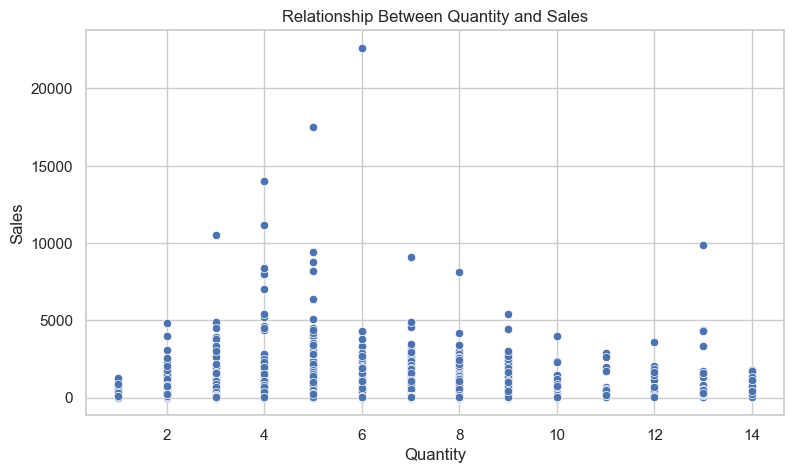

In [52]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Sales"
)

plt.title("Relationship Between Quantity and Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()

In [53]:
print("========== RETAIL BUSINESS ANALYSIS ==========")

print("\n1. Overall Performance")
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))

print("\n2. Best Performing Category")
print(category_analysis["Sales"].idxmax())

print("\n3. Most Profitable Category")
print(category_analysis["Profit"].idxmax())

print("\n4. Best Performing Region")
print(region_analysis["Sales"].idxmax())

print("\n5. Most Profitable Region")
print(region_analysis["Profit"].idxmax())

print("\n6. Top Selling Sub-Category")
print(subcategory_analysis["Sales"].idxmax())

print("\n7. Most Profitable Sub-Category")
print(subcategory_analysis["Profit"].idxmax())

print("\n8. Discount and Profit Correlation")
print(round(discount_correlation, 3))

print("\n9. Average Shipping Time")
print(round(df["Shipping Days"].mean(), 2), "days")

print("\n10. Hypothesis Testing P-Value")
print(round(p_value, 6))

print("\n========== ANALYSIS COMPLETED ==========")

========== RETAIL BUSINESS ANALYSIS ==========

1. Overall Performance
Total Sales: 2297200.86
Total Profit: 286397.02

2. Best Performing Category
Technology

3. Most Profitable Category
Technology

4. Best Performing Region
West

5. Most Profitable Region
West

6. Top Selling Sub-Category
Phones

7. Most Profitable Sub-Category
Copiers

8. Discount and Profit Correlation
-0.219

9. Average Shipping Time
3.96 days

10. Hypothesis Testing P-Value
0.0

========== ANALYSIS COMPLETED ==========


In [54]:
category_analysis.to_csv("Category_Analysis.csv")
region_analysis.to_csv("Region_Analysis.csv")
subcategory_analysis.to_csv("Subcategory_Analysis.csv")
shipping_analysis.to_csv("Shipping_Analysis.csv")

print("All Analysis Files Exported Successfully")

All Analysis Files Exported Successfully
